# Hyser, all participants: timing, forecast and day-to-day transfer

Second stage of the Hyser analysis. `hyser.ipynb` ran the tests on one participant; this notebook runs them on all 20.

**Data.** Hyser random task (PhysioNet `hd-semg` 2.0.0), subjects 1–20, trials 1 and 2 of sessions 1 and 2. The two sessions were recorded on separate days, so the electrodes were placed again. Download with `python download_hyser.py` (about 2 GB) or set `HYSER_RANDOM` to the folder that holds the `subjectXX_sessionY` folders.

The methods follow `hyser.ipynb`: causal sEMG features, calibration on one recording and testing on another, middle finger force.

1. **Timing (Figure 6).** The delay at which the sEMG predicts force best.
2. **Forecast (Figure 7).** Error reduction against repeating the model's own estimate (baseline 1), by phase and horizon.
3. **Day-to-day transfer (Figure 8).** A model calibrated on session 1 is tested on session 2, as it is and after a short calibration on the new day.

Results for each person are cached in `results/multisubject/`, so the notebook only processes new participants when it is run again.

In [1]:
import os, json, re, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfilt, welch
from scipy.stats import wilcoxon
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from IPython.display import Image, display
warnings.filterwarnings("ignore")
%matplotlib inline

REPO_DIR = Path.cwd()  # run the notebook from the repository folder
HYSER_RANDOM = os.environ.get("HYSER_RANDOM", "data/hyser")
FIG_DIR, RES_DIR = REPO_DIR / "figures", REPO_DIR / "results"
CACHE_DIR = RES_DIR / "multisubject"
for d in (FIG_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)
SUBJECTS = range(1, 21)

In [2]:
FS_EMG, FS_F = 2048, 100                  # Hz
FINGERS = ["thumb", "index", "middle", "ring", "little"]
GRIDS = ["ED", "EP", "FD", "FP"]
TARGET = "middle"
START, HMAX = 100, 20                     # skip the first 1 s; keep 200 ms at the end for future targets
HORIZONS_MS = [30, 50, 70, 100, 150, 200]
LAGS = (0, 3, 6)
K_PCA = 16
ALPHAS = [1.0, 10.0, 100.0, 1000.0]
WIN_MS = 50
PHASES = ["rising", "steady", "falling"]
MODELS = ["EMG forecast", "baseline 1: own estimate", "baseline 2: measured force"]
RECAL_S = (5, 10, 15, 20)                 # seconds of the new session used for calibration
N_BOOT, BLOCK = 500, 100
SEED = 7
CACHE_VERSION = 6
DELAYS_MS = list(range(-100, 310, 10))   # delays from the sEMG features to force

BLUE, ORANGE, INK, INK2, MUTED, GRIDLINE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#8c8b86", "#e4e3de"


def setup():
    import logging
    from matplotlib import font_manager as fm
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
    avail = {f.name for f in fm.fontManager.ttflist}
    fam = next((f for f in ["Calibri", "Carlito", "Segoe UI", "Arial"] if f in avail), "DejaVu Sans")
    plt.rcParams.update({
        "font.family": fam, "font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
        "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
        "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRIDLINE, "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 8,
        "lines.linewidth": 1.6, "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
        "figure.facecolor": "white", "axes.facecolor": "white"})


def save(fig, name):
    path = FIG_DIR / name
    fig.savefig(path)
    plt.close(fig)
    display(Image(filename=str(path), width=900))
    print("saved", path.relative_to(REPO_DIR))


setup()

## Reading, electrode check, features and models

Same functions as `hyser.ipynb`.

In [3]:
def read_hea(path):
    with open(path) as f:
        L = [l.strip() for l in f if l.strip() and not l.startswith("#")]
    name, nsig, fs, nsamp = L[0].split()[:4]
    sig = []
    for l in L[1:1 + int(nsig)]:
        p = l.split()
        g = p[2].split("/")[0]
        if "(" in g:
            gain, base = float(g[:g.index("(")]), int(g[g.index("(") + 1:g.index(")")])
        else:
            gain, base = float(g), (int(p[4]) if len(p) > 4 else 0)
        sig.append(dict(file=p[0], fmt=p[1], gain=gain if gain != 0 else 200.0, base=base,
                        name=p[8] if len(p) > 8 else f"ch{len(sig)}"))
    return dict(nsig=int(nsig), nsamp=int(nsamp), sig=sig)


def read_record(stem):
    """WFDB record (format 16) as samples x channels, in physical units."""
    h = read_hea(stem + ".hea")
    d = np.fromfile(os.path.join(os.path.dirname(stem), h["sig"][0]["file"]), dtype="<i2")
    if d.size != h["nsig"] * h["nsamp"]:
        raise ValueError(f"{stem}.dat is incomplete")
    d = d.reshape(h["nsamp"], h["nsig"]).astype(np.float64)
    g = np.array([s["gain"] for s in h["sig"]])
    b = np.array([s["base"] for s in h["sig"]])
    return ((d - b) / g).astype(np.float32), [s["name"] for s in h["sig"]]


def trial_path(s, session, n):
    return os.path.join(HYSER_RANDOM, f"subject{s:02d}_session{session}", f"random_{{}}_sample{n}")


def available(s, session):
    return all(os.path.exists(trial_path(s, session, n).format(k) + ext)
               for n in (1, 2) for k in ("raw", "force") for ext in (".hea", ".dat"))


def load_trial(s, session, n):
    stem = trial_path(s, session, n)
    emg, names = read_record(stem.format("raw"))
    force, _ = read_record(stem.format("force"))
    return emg, force.astype(np.float64), names


def channel_qc(emg, names):
    """Electrodes with abnormal amplitude, mains interference, spikes, or unlike their neighbours."""
    sos = butter(4, [20, 450], btype="band", fs=FS_EMG, output="sos")
    y = sosfilt(sos, emg, axis=0)[FS_EMG:]
    rms = np.sqrt(np.mean(y.astype(np.float64) ** 2, 0))
    f, P = welch(emg[FS_EMG:], fs=FS_EMG, nperseg=2048, axis=0)
    band = (f >= 20) & (f <= 450)
    line = np.zeros_like(f, bool)
    for k in range(50, 451, 50):
        line |= np.abs(f - k) <= 1
    line_ratio = P[line & band].sum(0) / P[band].sum(0)
    z = (y - y.mean(0)) / y.std(0)
    kurt = np.mean(z.astype(np.float64) ** 4, 0)
    c = np.vstack([np.zeros((1, y.shape[1])), np.cumsum(y.astype(np.float64) ** 2, 0)])
    w = int(0.05 * FS_EMG)
    env = np.sqrt((c[w::20] - c[:-w:20][:len(c[w::20])]) / w)
    zr, zk = np.zeros(len(names)), np.zeros(len(names))
    for G in GRIDS:
        idx = [i for i, nm in enumerate(names) if nm.startswith(G)]
        for v, out in [(np.log(rms), zr), (np.log(kurt), zk)]:
            med = np.median(v[idx]); mad = 1.4826 * np.median(np.abs(v[idx] - med))
            out[idx] = (v[idx] - med) / mad
    flags = {}
    for i, nm in enumerate(names):
        why = []
        if abs(zr[i]) > 5: why.append("amplitude")
        if line_ratio[i] > 0.3: why.append("mains interference")
        if zk[i] > 4 and kurt[i] > 50: why.append("spikes")
        if why: flags[nm] = why
    pos = {}
    for i, nm in enumerate(names):
        g, r, cc = nm.split("-")
        pos[(g, int(r), int(cc))] = i
    for (g, r, cc), i in pos.items():
        nb = [pos[(g, r + a, cc + b)] for a, b in [(-1, 0), (1, 0), (0, -1), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]
              if (g, r + a, cc + b) in pos and names[pos[(g, r + a, cc + b)]] not in flags]
        if nb and np.corrcoef(env[:, i], np.median(env[:, nb], 1))[0, 1] < 0.5:
            flags.setdefault(names[i], []).append("unlike neighbours")
    return flags


def envelope(emg, win_ms=WIN_MS):
    """Causal: band-pass 20-450 Hz, then trailing RMS sampled at the force timestamps (EMG up to t only)."""
    sos = butter(4, [20, 450], btype="band", fs=FS_EMG, output="sos")
    x = sosfilt(sos, emg, axis=0).astype(np.float64) ** 2
    c = np.vstack([np.zeros((1, x.shape[1])), np.cumsum(x, 0)])
    n_f = int(np.floor(emg.shape[0] / FS_EMG * FS_F))
    w = max(1, int(round(win_ms / 1000 * FS_EMG)))
    idx = np.clip(np.floor(np.arange(n_f) / FS_F * FS_EMG).astype(int) + 1, 1, emg.shape[0])
    lo = np.clip(idx - w, 0, None)
    return np.sqrt((c[idx] - c[lo]) / np.maximum(idx - lo, 1)[:, None])


class FrontEnd:
    """z-score and PCA, both fitted on calibration samples."""
    def fit(self, L, idx):
        self.mu, self.sd = L[idx].mean(0), L[idx].std(0) + 1e-9
        self.pca = PCA(n_components=K_PCA, random_state=0).fit((L[idx] - self.mu) / self.sd)
        self.scale = np.sqrt(self.pca.explained_variance_) + 1e-9
        return self

    def transform(self, L):
        return self.pca.transform((L - self.mu) / self.sd) / self.scale


def shift(Z, L):
    out = np.zeros_like(Z)
    if L == 0:
        return Z.copy()
    out[L:] = Z[:-L]
    return out


def design(Z):
    return np.hstack([shift(Z, L) for L in LAGS])


def eval_idx(n):
    return np.arange(START, n - HMAX)


def blocked_folds(idx, n=5, gap=50, h=0):
    g = gap + abs(h)
    for b in np.array_split(idx, n):
        yield idx[(idx < b[0] - g) | (idx > b[-1] + g)], b


def select_alpha(X, y, idx, h):
    """Ridge penalty chosen by blocked cross-validation inside the calibration data."""
    best = None
    for a in ALPHAS:
        sse = sum(np.sum((Ridge(alpha=a).fit(X[tr], y[tr + h]).predict(X[va]) - y[va + h]) ** 2)
                  for tr, va in blocked_folds(idx, h=h))
        if best is None or sse < best[1]:
            best = (a, sse)
    return best[0]


def r2(p, y):
    return float(1 - np.sum((p - y) ** 2) / np.sum((y - y.mean()) ** 2))


def rest_level(y):
    return float(np.median(y[:50]))


def phase_labels(y, rest, ref):
    """Evaluation only: rising / falling / steady / rest from the measured force (centred smoothing)."""
    a = np.abs(y - rest)
    sm = np.convolve(a, np.ones(5) / 5, mode="same")
    d = np.zeros_like(sm)
    d[5:-5] = sm[10:] - sm[:-10]
    thr, near = 0.15 * ref, 0.10 * ref
    lab = np.full(len(y), "steady", dtype=object)
    lab[d > thr] = "rising"
    lab[d < -thr] = "falling"
    lab[(np.abs(d) <= thr) & (sm <= near)] = "rest"
    return lab

## Analysis for one person

**Delay of best prediction.** Ridge models from the causal sEMG features at *t* to the middle finger force at *t* + *d*, for *d* from −100 to 300 ms, calibrated on one session-1 trial and scored (R²) on the other, both directions. The delay with the highest R² is how far ahead the sEMG carries most information about force, using whole recordings rather than single onsets.


**Forecast.** Calibrate on one session-1 trial, test on the other, both directions. Gain = error of baseline 1 minus error of the sEMG forecast, in points of a typical press (positive = the forecast helps), with a moving-block bootstrap interval within the person. The middle finger counts as active in a trial when its typical press (95th percentile of the force change) is at least 10 times its rest noise.

**Day-to-day transfer.** Test recording: session 2, trial 2. Calibration: session 1, trial 1 (as it is, or with the sEMG normalisation updated on the first seconds of session 2, trial 1, which needs no force), or the first seconds of session 2, trial 1 with force (together with session 1, or alone). Reference: the same model calibrated on the whole of session 2, trial 1. Score: R² of the middle finger force estimate (h = 0) and of the forecast at 100 ms. Electrodes excluded on session 1 stay excluded; the electrode check is not repeated on session 2, as in a device that cannot re-check them.

In [4]:
J = FINGERS.index(TARGET)


def delay_profile(TR):
    """R2 of the middle finger force at t + d from the causal sEMG features at t, for each delay d in DELAYS_MS.
    Calibrate on one session-1 trial, test on the other; mean of both directions."""
    prof = np.zeros(len(DELAYS_MS))
    hi = max(DELAYS_MS) // 10
    for cal, tst in [(1, 2), (2, 1)]:
        yA, yB = TR[cal]["F"][:, J], TR[tst]["F"][:, J]
        idxA, idxB = np.arange(START, len(yA) - hi), np.arange(START, len(yB) - hi)
        fe = FrontEnd().fit(TR[cal]["L"], idxA)
        XA, XB = design(fe.transform(TR[cal]["L"])), design(fe.transform(TR[tst]["L"]))
        for k, dm in enumerate(DELAYS_MS):
            d = dm // 10
            P = Ridge(alpha=select_alpha(XA, yA, idxA, d)).fit(XA[idxA], yA[idxA + d]).predict(XB)
            prof[k] += r2(P[idxB], yB[idxB + d]) / 2
    return [round(float(v), 4) for v in prof]


def fit_predict(Lc, yc, idxc, Lt, h, fe=None, fe_test=None):
    """Ridge forecast at horizon h fitted on calibration samples idxc, applied to the test recording.
    fe_test: front end for the test recording (default: the calibration one)."""
    fe = fe or FrontEnd().fit(Lc, idxc)
    Xc, Xt = design(fe.transform(Lc)), design((fe_test or fe).transform(Lt))
    return Ridge(alpha=select_alpha(Xc, yc, idxc, h)).fit(Xc[idxc], yc[idxc + h]).predict(Xt)


def active_finger(y):
    """The finger counts as active when its typical press is at least 10 times its rest noise."""
    idx = eval_idx(len(y))
    return bool(np.percentile(np.abs(y[idx] - rest_level(y)), 95) >= 10 * (np.std(y[:50]) + 1e-9))


def forecast(TR):
    """Errors on session 1 (calibrate on one trial, test on the other). Returns errors, phase labels and activity check."""
    E, LAB, active = {}, {}, {}
    for cal, tst in [(1, 2), (2, 1)]:
        yA, yB = TR[cal]["F"][:, J], TR[tst]["F"][:, J]
        idxA, idxB = eval_idx(len(yA)), eval_idx(len(yB))
        restA, restB = rest_level(yA), rest_level(yB)
        scale = np.percentile(np.abs(yB[idxB] - restB), 95)
        active[tst] = active_finger(yB)
        phase = phase_labels(yB, restB, np.percentile(np.abs(yA[idxA] - restA), 95))
        fe = FrontEnd().fit(TR[cal]["L"], idxA)
        now = fit_predict(TR[cal]["L"], yA, idxA, TR[tst]["L"], 0, fe)
        for hm in HORIZONS_MS:
            h = hm // 10
            P = fit_predict(TR[cal]["L"], yA, idxA, TR[tst]["L"], h, fe)
            LAB[(cal, hm)] = phase[idxB + h]
            for nm, v in zip(MODELS, [P, now, yB]):
                E[(cal, nm, hm)] = ((v[idxB] - yB[idxB + h]) / scale) ** 2
    return E, LAB, active


def rmse(E, LAB, nm, p, hm, sel=None):
    s = c = 0.0
    for cal in (1, 2):
        e, lab = E[(cal, nm, hm)], LAB[(cal, hm)]
        if sel is not None:
            e, lab = e[sel[cal]], lab[sel[cal]]
        m = lab == p
        s, c = s + e[m].sum(), c + m.sum()
    return 100 * np.sqrt(s / c) if c else np.nan


def gains(E, LAB, rng):
    """Gain of the sEMG forecast over baselines 1 and 2, with a moving-block bootstrap interval."""
    n = {cal: len(LAB[(cal, HORIZONS_MS[0])]) for cal in (1, 2)}
    out = {}
    for b in MODELS[1:]:
        est = {p: [rmse(E, LAB, b, p, hm) - rmse(E, LAB, MODELS[0], p, hm) for hm in HORIZONS_MS] for p in PHASES}
        boot = np.full((N_BOOT, len(PHASES), len(HORIZONS_MS)), np.nan)
        for r in range(N_BOOT):
            sel = {}
            for cal in (1, 2):
                st = rng.integers(0, n[cal], int(np.ceil(n[cal] / BLOCK)))
                sel[cal] = ((st[:, None] + np.arange(BLOCK)[None]).ravel()[:n[cal]]) % n[cal]
            for i, p in enumerate(PHASES):
                for k, hm in enumerate(HORIZONS_MS):
                    boot[r, i, k] = rmse(E, LAB, b, p, hm, sel) - rmse(E, LAB, MODELS[0], p, hm, sel)
        lo, hi = np.nanpercentile(boot, 2.5, 0), np.nanpercentile(boot, 97.5, 0)
        out[b] = {p: dict(gain=[round(float(v), 2) for v in est[p]], ci95=[[round(float(lo[i, k]), 2), round(float(hi[i, k]), 2)]
                                                                     for k in range(len(HORIZONS_MS))])
                  for i, p in enumerate(PHASES)}
    return out


def transfer(TR, TR2):
    """Session 1 -> session 2 for the middle finger: R2 at h = 0 and 100 ms for each calibration strategy."""
    L1, y1 = TR[1]["L"], TR[1]["F"][:, J]
    La, ya = TR2[1]["L"], TR2[1]["F"][:, J]                   # session 2, trial 1: new-day calibration data
    Lt, yt = TR2[2]["L"], TR2[2]["F"][:, J]                   # session 2, trial 2: test
    i1, ia, it = eval_idx(len(y1)), eval_idx(len(ya)), eval_idx(len(yt))
    out = {}
    for hm in (0, 100):
        h = hm // 10
        score = lambda P: round(r2(P[it], yt[it + h]), 3)
        res = dict(same_day=score(fit_predict(La, ya, ia, Lt, h)), previous_day=score(fit_predict(L1, y1, i1, Lt, h)))
        for sec in RECAL_S:
            ik = ia[ia < START + sec * FS_F]
            fe = FrontEnd().fit(L1, i1)
            fe_new = FrontEnd()
            fe_new.pca, fe_new.scale = fe.pca, fe.scale
            fe_new.mu, fe_new.sd = La[ik].mean(0), La[ik].std(0) + 1e-9   # new-day normalisation, sEMG only
            res[f"renormalised_{sec}s"] = score(fit_predict(L1, y1, i1, Lt, h, fe, fe_new))
            Lc = np.vstack([L1, La[:ik[-1] + HMAX + 1]])
            yc = np.concatenate([y1, ya[:ik[-1] + HMAX + 1]])
            ic = np.concatenate([i1, len(y1) + ik])
            res[f"both_days_{sec}s"] = score(fit_predict(Lc, yc, ic, Lt, h))
            res[f"new_day_only_{sec}s"] = score(fit_predict(La, ya, ik, Lt, h))
        out[f"h{hm}"] = res
    return out


def analyse(s):
    path = CACHE_DIR / f"subject{s:02d}.json"
    if path.exists():
        r = json.loads(path.read_text())
        if r.get("version") == CACHE_VERSION and (r["transfer_r2"] is not None or not available(s, 2)):
            return r                                           # otherwise redo (new version, or session 2 now downloaded)
    if not available(s, 1):
        return None
    rng = np.random.default_rng(SEED + s)
    TR, bad, names = {}, set(), None
    for n in (1, 2):
        emg, F, names = load_trial(s, 1, n)
        bad |= set(channel_qc(emg, names))
        TR[n] = dict(emg=emg, F=F)
    keep = np.array([nm not in bad for nm in names])
    res = dict(version=CACHE_VERSION, subject=s, excluded_electrodes=sorted(bad))
    for n in (1, 2):
        TR[n]["L"] = np.log(envelope(TR[n].pop("emg")[:, keep]) + 1e-7)
    res["delay_profile_r2"] = delay_profile(TR)
    E, LAB, active = forecast(TR)
    res["middle_finger_active"] = {str(k): v for k, v in active.items()}
    res["error_percent"] = {p: {nm: [round(float(rmse(E, LAB, nm, p, hm)), 2) for hm in HORIZONS_MS] for nm in MODELS} for p in PHASES}
    res["gain_points"] = gains(E, LAB, rng)
    res["transfer_r2"] = None
    if available(s, 2):
        TR2 = {}
        for n in (1, 2):
            emg, F, _ = load_trial(s, 2, n)
            TR2[n] = dict(F=F, L=np.log(envelope(emg[:, keep]) + 1e-7))
            del emg
        res["transfer_r2"] = transfer(TR, TR2)
        res["middle_finger_active_session2"] = {str(n): active_finger(TR2[n]["F"][:, J]) for n in (1, 2)}
    path.write_text(json.dumps(res))
    return res

## Run all participants

In [5]:
RES = {}
for s in SUBJECTS:
    r = analyse(s)
    if r is None:
        print(f"subject {s:02d}: files not found")
        continue
    RES[s] = r
    best = DELAYS_MS[int(np.argmax(r["delay_profile_r2"]))]
    g = r["gain_points"]["baseline 1: own estimate"]["rising"]["gain"][HORIZONS_MS.index(100)]
    tr = r["transfer_r2"]["h0"] if r["transfer_r2"] else None
    print(f"subject {s:02d}: {len(r['excluded_electrodes'])} electrodes excluded | best delay {best} ms | "
          f"gain at 100 ms, force rising {g:+.1f} | R2 next day {tr['previous_day'] if tr else '-'} "
          f"(same day {tr['same_day'] if tr else '-'})")
print(f"\n{len(RES)} participants")

subject 01: 5 electrodes excluded | best delay 70 ms | gain at 100 ms, force rising +0.9 | R2 next day 0.637 (same day 0.676)
subject 02: 13 electrodes excluded | best delay 20 ms | gain at 100 ms, force rising -0.6 | R2 next day -0.422 (same day 0.067)
subject 03: 21 electrodes excluded | best delay 300 ms | gain at 100 ms, force rising -0.1 | R2 next day -0.174 (same day 0.52)
subject 04: 15 electrodes excluded | best delay 220 ms | gain at 100 ms, force rising +1.4 | R2 next day 0.557 (same day 0.509)
subject 05: 11 electrodes excluded | best delay 140 ms | gain at 100 ms, force rising +4.0 | R2 next day 0.318 (same day 0.826)
subject 06: 6 electrodes excluded | best delay 140 ms | gain at 100 ms, force rising +4.5 | R2 next day -0.048 (same day 0.249)
subject 07: 8 electrodes excluded | best delay 280 ms | gain at 100 ms, force rising +2.1 | R2 next day -0.167 (same day 0.392)
subject 08: 22 electrodes excluded | best delay 130 ms | gain at 100 ms, force rising -0.2 | R2 next day -

## Figure 6 · Timing across participants

**a.** R² of each person relative to their best delay (thin lines; participants with an active middle finger), median in black. **b.** R² at 0 ms and at each person's best delay.

delay of best prediction (19 participants): median 130 ms, IQR [105, 195] ms, range 20 to 300 ms
R2 at 0 ms: median 0.18; at the best delay: median 0.36; difference median 0.149, IQR [0.044, 0.297]
people whose best delay is after 0 ms: 19 of 19


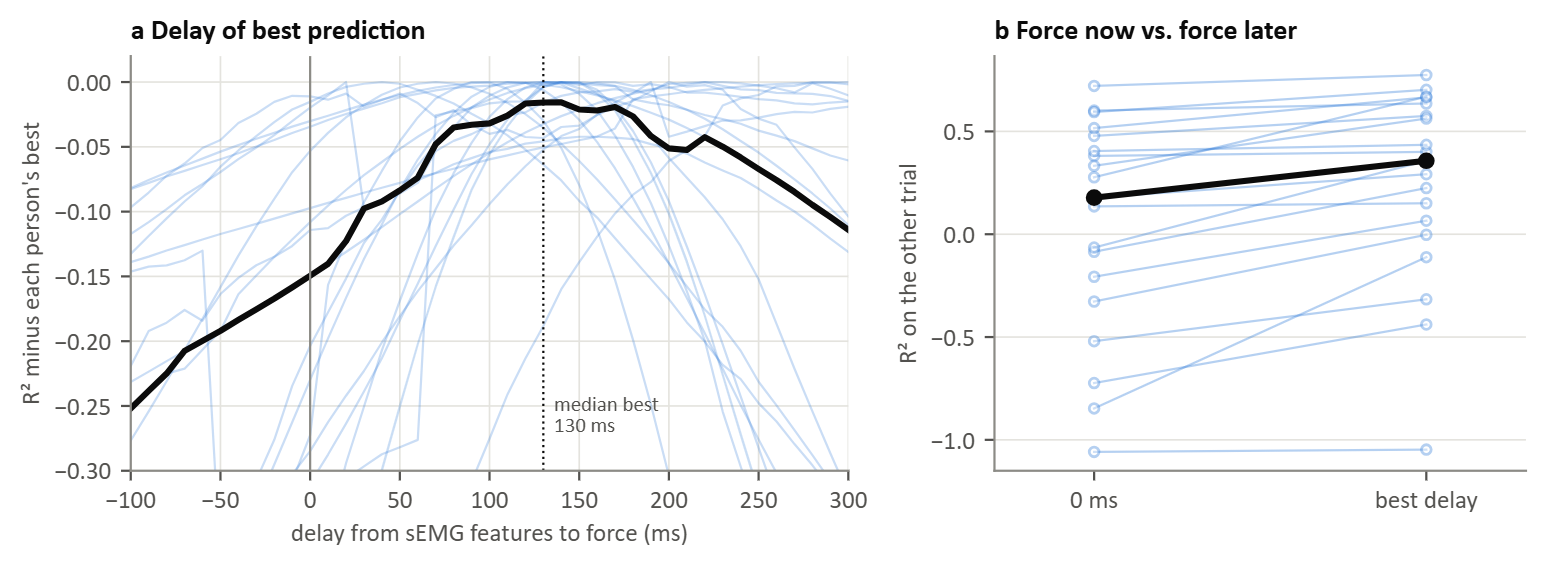

saved figures/figure6.png


In [6]:
OK = [s for s, r in RES.items() if all(r["middle_finger_active"].values())]
DP = np.array([RES[s]["delay_profile_r2"] for s in OK])
BEST_D = np.array([DELAYS_MS[int(np.argmax(v))] for v in DP])
i0 = DELAYS_MS.index(0)
r0, rb = DP[:, i0], DP.max(1)
print(f"delay of best prediction ({len(OK)} participants): median {np.median(BEST_D):.0f} ms, IQR [{np.percentile(BEST_D, 25):.0f}, {np.percentile(BEST_D, 75):.0f}] ms, "
      f"range {BEST_D.min()} to {BEST_D.max()} ms")
print(f"R2 at 0 ms: median {np.median(r0):.2f}; at the best delay: median {np.median(rb):.2f}; "
      f"difference median {np.median(rb - r0):.3f}, IQR [{np.percentile(rb - r0, 25):.3f}, {np.percentile(rb - r0, 75):.3f}]")
print("people whose best delay is after 0 ms:", int(np.sum(BEST_D > 0)), "of", len(BEST_D))

fig, axs = plt.subplots(1, 2, figsize=(7.8, 2.9), gridspec_kw=dict(width_ratios=[1.35, 1]))
ax = axs[0]
for v in DP:
    ax.plot(DELAYS_MS, v - v.max(), color=BLUE, alpha=0.25, lw=0.8)
ax.plot(DELAYS_MS, np.median(DP - DP.max(1, keepdims=True), 0), color=INK, lw=2.2)
ax.axvline(np.median(BEST_D), color=INK, lw=0.8, ls=":")
ax.axvline(0, color=MUTED, lw=0.8)
ax.text(np.median(BEST_D) + 6, -0.27, f"median best\n{np.median(BEST_D):.0f} ms", fontsize=7.5, color=INK2)
ax.set_xlim(min(DELAYS_MS), max(DELAYS_MS)); ax.set_ylim(-0.3, 0.02)
ax.set_xlabel("delay from sEMG features to force (ms)"); ax.set_ylabel("R² minus each person's best")
ax.set_title("a  Delay of best prediction")
ax = axs[1]
for a0, ab in zip(r0, rb):
    ax.plot([0, 1], [a0, ab], color=BLUE, alpha=0.35, lw=0.8, marker="o", ms=3.5, mfc="white")
ax.plot([0, 1], [np.median(r0), np.median(rb)], color=INK, lw=2.2, marker="o", ms=5)
ax.set_xticks([0, 1]); ax.set_xticklabels(["0 ms", "best delay"]); ax.set_xlim(-0.3, 1.3)
ax.set_ylabel("R² on the other trial"); ax.grid(axis="x", visible=False)
ax.set_title("b  Force now vs. force later")
fig.tight_layout(w_pad=1.2)
save(fig, "figure6.png")

## Figure 7 · Forecast gain across participants

Error reduction of the sEMG forecast against baseline 1, one thin line per person (middle finger active in both trials). Thick line: median. The table counts the people whose own 95% interval lies above zero, and tests the median gain across people (Wilcoxon signed-rank).

middle finger active in both trials: 19 of 20 participants

baseline 1: own estimate minus sEMG forecast (points of a typical press)
  rising     30 ms  +0.0 (4+/1-, p=0.157)   50 ms  +0.1 (3+/0-, p=0.153)   70 ms  +0.3 (3+/0-, p=0.023)  100 ms  +1.4 (5+/1-, p=0.001)  150 ms  +3.3 (10+/1-, p=0.000)  200 ms  +3.7 (10+/1-, p=0.000)
  steady     30 ms  +0.3 (7+/1-, p=0.010)   50 ms  +0.3 (9+/3-, p=0.045)   70 ms  +0.7 (10+/3-, p=0.016)  100 ms  +0.9 (10+/3-, p=0.027)  150 ms  +0.9 (8+/2-, p=0.066)  200 ms  +0.5 (5+/2-, p=0.295)
  falling    30 ms  +0.1 (6+/0-, p=0.349)   50 ms  +0.3 (6+/1-, p=0.033)   70 ms  +0.7 (4+/1-, p=0.004)  100 ms  +1.4 (6+/0-, p=0.015)  150 ms  +1.1 (7+/1-, p=0.030)  200 ms  +1.8 (6+/2-, p=0.182)

baseline 2: measured force minus sEMG forecast (points of a typical press)
  rising     30 ms -28.9 (0+/19-, p=0.000)   50 ms -23.9 (0+/18-, p=0.000)   70 ms -18.5 (0+/14-, p=0.000)  100 ms -12.3 (3+/6-, p=0.023)  150 ms  -0.7 (6+/3-, p=0.953)  200 ms  +4.8 (7+/3-, p=0.4

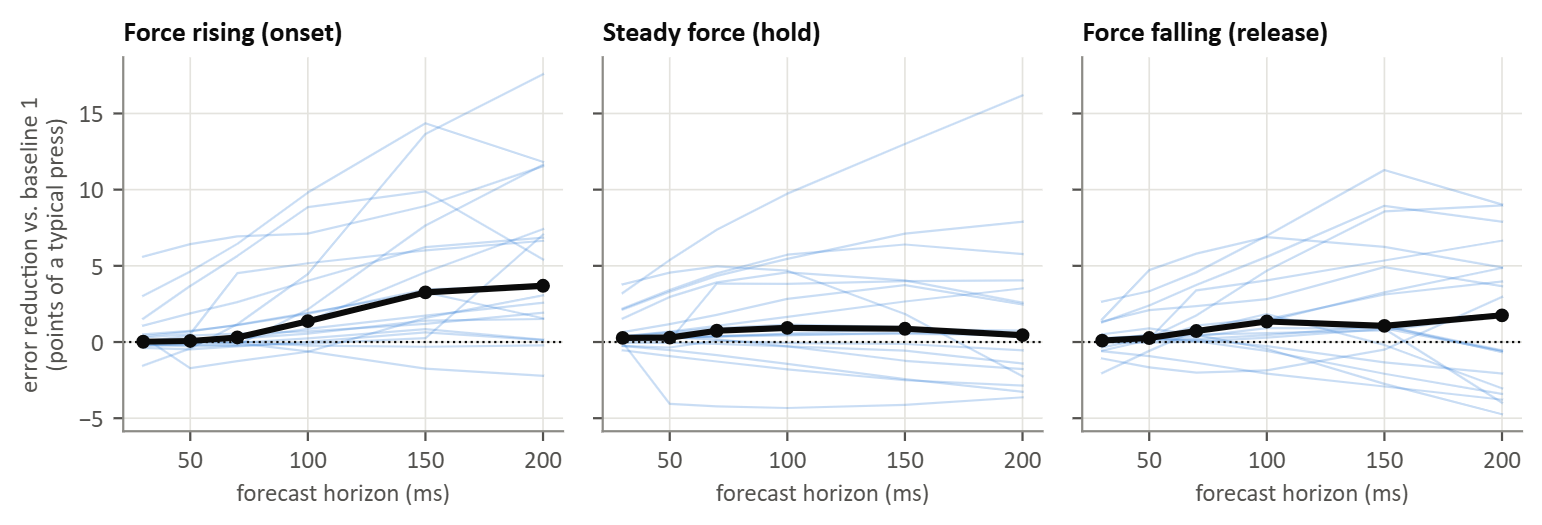

saved figures/figure7.png


In [7]:
print(f"middle finger active in both trials: {len(OK)} of {len(RES)} participants\n")
assert OK, "no participant with an active middle finger"
GROUP = {}
for b in MODELS[1:]:
    GROUP[b] = {}
    print(f"{b} minus sEMG forecast (points of a typical press)")
    for p in PHASES:
        G = np.array([RES[s]["gain_points"][b][p]["gain"] for s in OK])
        LO = np.array([[c[0] for c in RES[s]["gain_points"][b][p]["ci95"]] for s in OK])
        HI = np.array([[c[1] for c in RES[s]["gain_points"][b][p]["ci95"]] for s in OK])
        rows = []
        for k, hm in enumerate(HORIZONS_MS):
            g = G[:, k][np.isfinite(G[:, k])]
            pval = float(wilcoxon(g).pvalue) if len(g) >= 6 else np.nan
            rows.append(dict(horizon_ms=hm, n=int(len(g)), median=round(float(np.median(g)), 2),
                             iqr=[round(float(np.percentile(g, 25)), 2), round(float(np.percentile(g, 75)), 2)],
                             people_above_zero=int(np.sum(LO[:, k] > 0)), people_below_zero=int(np.sum(HI[:, k] < 0)),
                             wilcoxon_p=round(pval, 4)))
        GROUP[b][p] = rows
        print(f"  {p:8s}" + "".join(f"  {r['horizon_ms']:>3} ms {r['median']:+5.1f} ({r['people_above_zero']}+/{r['people_below_zero']}-, p={r['wilcoxon_p']:.3f})" for r in rows))
    print()

fig, axs = plt.subplots(1, 3, figsize=(7.8, 2.7), sharey=True)
for ax, p, title in zip(axs, PHASES, ["Force rising (onset)", "Steady force (hold)", "Force falling (release)"]):
    G = np.array([RES[s]["gain_points"]["baseline 1: own estimate"][p]["gain"] for s in OK])
    for g in G:
        ax.plot(HORIZONS_MS, g, color=BLUE, alpha=0.25, lw=0.8)
    ax.plot(HORIZONS_MS, np.nanmedian(G, 0), color=INK, lw=2.2, marker="o", ms=4)
    ax.axhline(0, color=INK, lw=0.8, ls=":")
    ax.set_title(title); ax.set_xlabel("forecast horizon (ms)"); ax.set_xticks([50, 100, 150, 200])
axs[0].set_ylabel("error reduction vs. baseline 1\n(points of a typical press)")
fig.tight_layout()
save(fig, "figure7.png")

## Figure 8 · Day-to-day transfer

R² on session 2, trial 2, for the middle finger force estimate (h = 0) and the forecast at 100 ms. Median across participants with both sessions and an active middle finger.

participants with both sessions and an active middle finger in all four trials: 19

Force estimate (h = 0): median R2 (IQR)
  same_day                  0.392  [ 0.223,  0.560]
  previous_day             -0.072  [-0.328,  0.202]
  renormalised_5s           0.010  [-0.566,  0.236]
  both_days_5s              0.238  [ 0.043,  0.309]
  new_day_only_5s          -0.061  [-0.319,  0.213]
  renormalised_10s          0.116  [-0.185,  0.265]
  both_days_10s             0.322  [ 0.104,  0.440]
  new_day_only_10s          0.069  [-0.059,  0.246]
  renormalised_15s          0.108  [-0.062,  0.282]
  both_days_15s             0.312  [ 0.199,  0.514]
  new_day_only_15s          0.222  [ 0.081,  0.451]
  renormalised_20s          0.110  [-0.093,  0.283]
  both_days_20s             0.350  [ 0.256,  0.514]
  new_day_only_20s          0.351  [ 0.184,  0.528]

Forecast, 100 ms ahead: median R2 (IQR)
  same_day                  0.581  [ 0.427,  0.675]
  previous_day              0.081  [-0.188,  0.264]
  r

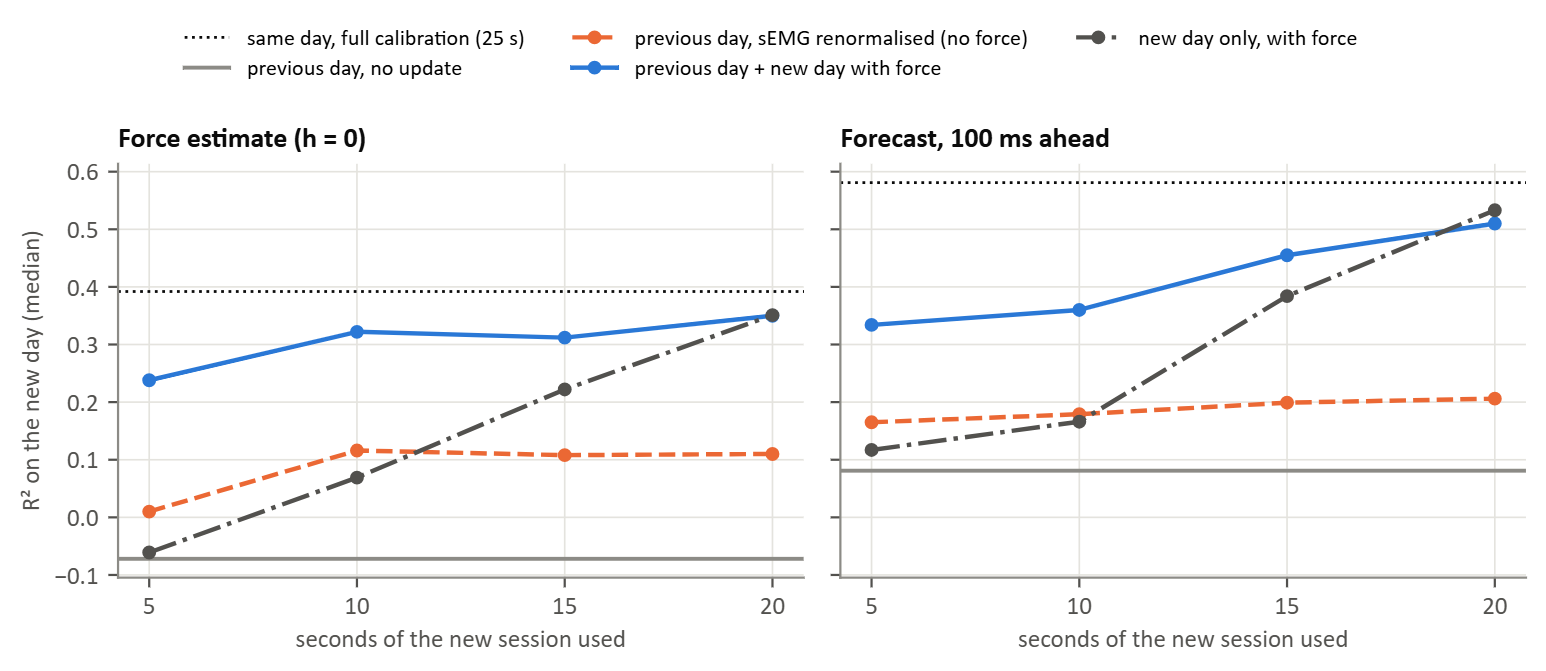

saved figures/figure8.png


In [8]:
OK2 = [s for s in OK if RES[s]["transfer_r2"] and all(RES[s]["middle_finger_active_session2"].values())]
print(f"participants with both sessions and an active middle finger in all four trials: {len(OK2)}")
assert OK2, "session 2 files not found"
STRATS = [("renormalised", "previous day, sEMG renormalised (no force)", ORANGE, "--"),
          ("both_days", "previous day + new day with force", BLUE, "-"),
          ("new_day_only", "new day only, with force", INK2, "-.")]
TRANSFER = {}
fig, axs = plt.subplots(1, 2, figsize=(7.8, 2.9), sharey=True)
for ax, hk, title in zip(axs, ("h0", "h100"), ("Force estimate (h = 0)", "Forecast, 100 ms ahead")):
    T = {k: np.array([RES[s]["transfer_r2"][hk][k] for s in OK2]) for k in RES[OK2[0]]["transfer_r2"][hk]}
    TRANSFER[hk] = {k: dict(median=round(float(np.median(v)), 3), iqr=[round(float(np.percentile(v, 25)), 3), round(float(np.percentile(v, 75)), 3)])
                    for k, v in T.items()}
    ax.axhline(np.median(T["same_day"]), color=INK, lw=1, ls=":", label="same day, full calibration (25 s)")
    ax.axhline(np.median(T["previous_day"]), color=MUTED, lw=1.4, label="previous day, no update")
    for key, lab, col, ls in STRATS:
        ax.plot(RECAL_S, [np.median(T[f"{key}_{sec}s"]) for sec in RECAL_S], color=col, ls=ls, marker="o", ms=4, label=lab)
    ax.set_title(title); ax.set_xlabel("seconds of the new session used"); ax.set_xticks(RECAL_S)
    print(f"\n{title}: median R2 (IQR)")
    for k, v in TRANSFER[hk].items():
        print(f"  {k:24s} {v['median']:6.3f}  [{v['iqr'][0]:6.3f}, {v['iqr'][1]:6.3f}]")
axs[0].set_ylabel("R² on the new day (median)")
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=3, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout()
save(fig, "figure8.png")

## Save the numbers

In [9]:
PERSON = {}
for s, r in RES.items():
    PERSON[str(s)] = dict(
        excluded_electrodes=len(r["excluded_electrodes"]),
        middle_finger_active=all(r["middle_finger_active"].values()),
        best_delay_ms=DELAYS_MS[int(np.argmax(r["delay_profile_r2"]))],
        r2_best_delay=max(r["delay_profile_r2"]), r2_zero_delay=r["delay_profile_r2"][DELAYS_MS.index(0)],
        gain_vs_baseline1={p: r["gain_points"]["baseline 1: own estimate"][p]["gain"] for p in PHASES},
        transfer_r2=r["transfer_r2"])
OUT = dict(participants=sorted(RES), middle_finger_active_both_trials=OK, both_sessions=OK2,
           delay_of_best_prediction=dict(delays_ms=DELAYS_MS, median_ms=float(np.median(BEST_D)),
                                         iqr_ms=[float(np.percentile(BEST_D, 25)), float(np.percentile(BEST_D, 75))],
                                         r2_at_0_median=float(np.median(r0)), r2_at_best_median=float(np.median(rb))),
           forecast_gain_group=GROUP, transfer_r2_group=TRANSFER, per_participant=PERSON,
           settings=dict(horizons_ms=HORIZONS_MS, recalibration_s=list(RECAL_S), bootstrap=N_BOOT, block_s=BLOCK / FS_F))
txt = json.dumps(OUT, indent=1)
txt = re.sub(r"\[\s+([^\[\]{}]*?)\s+\]", lambda m: "[" + re.sub(r"\s+", " ", m.group(1)) + "]", txt)
(RES_DIR / "hyser_multisubject.json").write_text(txt + "\n")
print("saved results/hyser_multisubject.json")

saved results/hyser_multisubject.json
